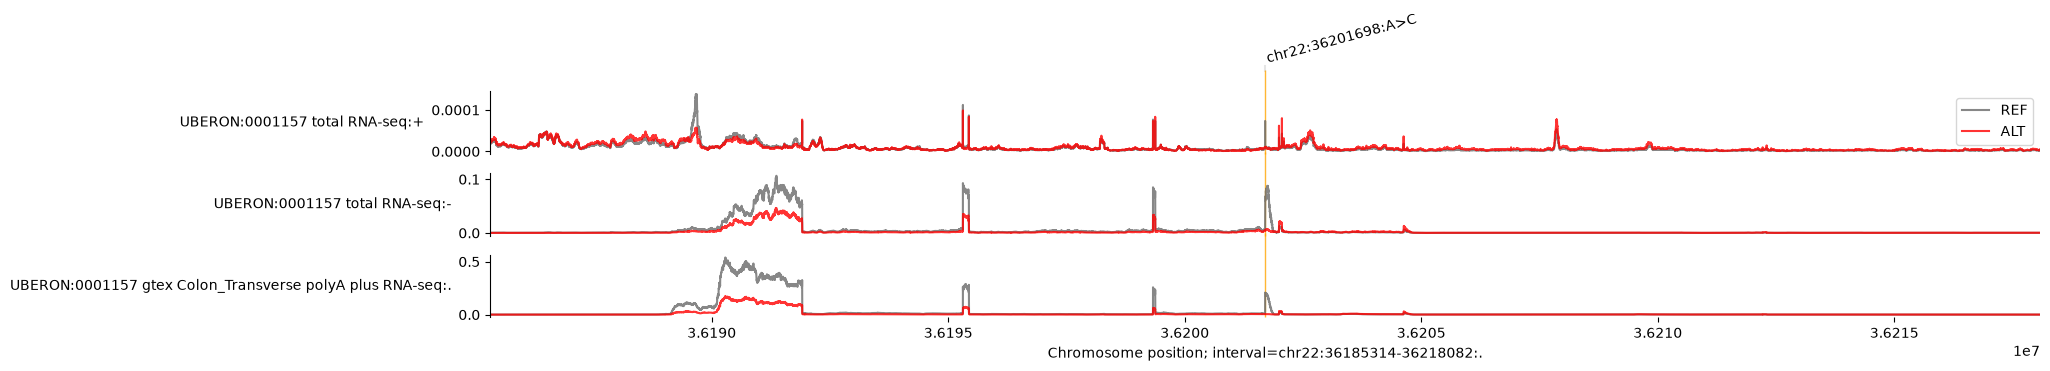

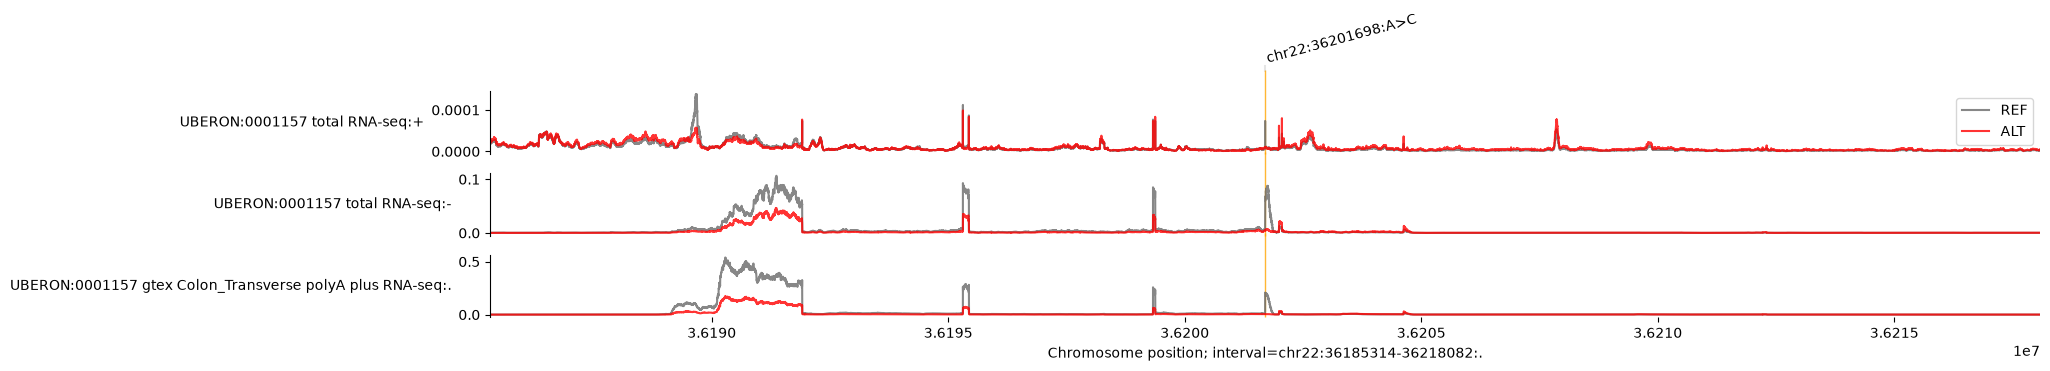

In [5]:
from alphagenome.data import genome
from alphagenome.models.v1 import dna_client
from alphagenome.visualization import plot_components
import matplotlib.pyplot as plt
import pathlib

ROOT = pathlib.Path('/storage/mathelierarea/processed/eirikhoy/action_var')


API_KEY = (ROOT / 'resources/API_KEY').read_text().strip()
model = dna_client.create(API_KEY)


interval = genome.Interval(chromosome='chr22', start=35677410, end=36725986)
variant = genome.Variant(
    chromosome='chr22',
    position=36201698,
    reference_bases='A',
    alternate_bases='C',
)

outputs = model.predict_variant(
    interval=interval,
    variant=variant,
    ontology_terms=['UBERON:0001157'],
    requested_outputs=[dna_client.OutputType.RNA_SEQ],
)

plot_components.plot(
    [
        plot_components.OverlaidTracks(
            tdata={
                'REF': outputs.reference.rna_seq,
                'ALT': outputs.alternate.rna_seq,
            },
            colors={'REF': 'dimgrey', 'ALT': 'red'},
        ),
    ],
    interval=outputs.reference.rna_seq.interval.resize(2**15),
    # Annotate the location of the variant as a vertical line.
    annotations=[plot_components.VariantAnnotation([variant], alpha=0.8)]
)